# DBMS Fundamentals: The Relational Model and Relational Algebra

> **Who is this for:** learners who can read a simple SQL query and want to know what is *really* going on underneath — and students preparing for DBMS exams/interviews, where keys, integrity constraints, relational algebra (especially **division**), and relational calculus are standard questions.
>
> **What you will learn:**
> - The relational model precisely: relation, tuple, attribute, domain, degree, cardinality, schema vs. instance, NULL
> - All kinds of **keys** (super, candidate, primary, alternate, foreign, composite, surrogate) and a brute-force **candidate-key finder** (and why data alone can't prove a key)
> - **Integrity constraints** (domain, entity, referential with `ON DELETE CASCADE / SET NULL`, key, check), enforced in SQLite
> - **Relational algebra**, implemented from scratch in Python: σ, π, ρ, ∪, −, ×, ∩, joins (theta, equi, natural, outer), semi-join, anti-join, division ÷, grouping/aggregation, assignment — **each checked against SQLite with `assert`**
> - 10 classic exam queries in algebra *and* SQL; expression trees and why the optimizer pushes selections down
> - Inner vs. outer joins; joins vs. nested queries (and the `NOT IN` + NULL trap)
> - **Tuple and domain relational calculus**, and what makes an expression *safe*
> - Codd's 12 rules, relational completeness, and row- vs. column-oriented storage
>
> **Prerequisites:** [01 — DBMS Introduction](01_dbms_introduction_and_architecture.ipynb), [02 — ER model](02_er_model_and_eer.ipynb), [Python basics](../../01_Python/01_basic.ipynb) (sets, dicts, functions). [SQL Fundamentals](../01_sql/01_sql_fundamentals.ipynb) helps for the SQL halves.
>
> **Time needed:** about 2.5 hours.
>
> **Runs on:** CPU, no API key, no internet. Uses `sqlite3`, `pandas`, `numpy`, `matplotlib`, `networkx`.
>
> **Optional track:** part of the *university-level fundamentals track*; recommended for BS/MS AI students and interview prep. Follows Silberschatz/Korth/Sudarshan ch. 2 and 27 (formal languages), Elmasri/Navathe ch. 5 and 8.

## Explained simply

The **relational model** is the maths behind every SQL table: a table (a *relation*) is a set of rows, each row describes one thing, and each column holds one kind of value. A **key** is a column, or a few columns, whose value is different in every row, like a student ID or a car's number plate, so you can always point to exactly one row. **Constraints** are rules the database checks on every change, such as "every enrolment must belong to a real student", like a bouncer checking every guest against the list. **Relational algebra** is a small set of operations on tables: keep some rows, keep some columns, glue two tables together, and a few more. It is like cooking with a few basic moves (chop, mix, heat) that combine into any recipe, and the database turns every SQL query into these moves before running it. Knowing them helps you write correct queries, understand pandas, and see why some queries are fast and others slow.

**Tiny example.** The `student` table has 6 rows: Ayesha, Bilal, Chen, Dina, Emre and Farah. *Selection* "keep the rows where dept = CS and year ≥ 3" leaves 2 rows, Bilal (year 3) and Emre (year 4). *Projection* "keep only the name column" then gives just `Bilal, Emre`. A harder question, "who took **every** CS course?", needs *division*: the CS courses are C1, C2 and C3; Ayesha, Bilal and Emre took all three, while Chen took only C1, so the answer is Ayesha, Bilal and Emre.

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| Relation (table) | a set of rows with named columns and no duplicate rows | every SQL table; a pandas DataFrame |
| Key | the column(s) that tell rows apart | student ID, email address, order number, `user_id` in a feature table |
| Relational algebra | a few basic table operations (filter, pick columns, join) that build any query | the query plan inside every database; `df[...]`, `merge` and `groupby` in pandas |

In [1]:
import sqlite3, itertools, time, math
from itertools import combinations
from collections import defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
pd.set_option("display.width", 130)

## 1. Relational Model Concepts

> 💡 **In plain English:** a relation is just a table with strict rules: no duplicate rows, no meaningful row order, and one value per cell.

**Analogy.** A relation is a table — but a *mathematical* table: no duplicate rows, no meaningful row order, and every cell holds a single value.

Formally (Codd, 1970):

- A **domain** `D` is a set of atomic (indivisible) values, e.g. `Years = {1, 2, 3, 4}`.
- A **relation schema** `R(A1, A2, …, An)` is a relation name plus a list of **attributes**; each attribute `Ai` has a domain `dom(Ai)`. Example: `STUDENT(sid, name, dept, year)`.
- A **relation** (relation *instance* / *state*) `r(R)` is a **set** of n-**tuples**, i.e. a subset of the Cartesian product `dom(A1) × … × dom(An)`.
- **Degree (arity)** = number of attributes `n`. **Cardinality** = number of tuples `|r|`.
- A **relational database schema** is a set of relation schemas + integrity constraints; a **database instance** is a set of relation instances.

| Informal term | Formal term |
|---|---|
| table | relation |
| row / record | tuple |
| column / field | attribute |
| column's data type / allowed values | domain |
| table definition (header) | relation schema |
| number of columns / rows | degree / cardinality |

Properties that follow from "a relation is a set": (1) no duplicate tuples; (2) tuples are unordered; (3) in the "set of mappings" view, attributes are unordered too; (4) values are **atomic** (first normal form); (5) a special value **NULL** represents unknown or inapplicable values — it is *not* a member of any domain and makes comparisons three-valued (`NULL = NULL` is *unknown*, not true).

We now build a tiny `Relation` class — it is the data structure for the rest of the notebook.

In [2]:
class Relation:
    """A relation = a schema (tuple of attribute names) + a SET of tuples (set semantics, no order)."""
    def __init__(self, attrs, rows=()):
        attrs = tuple(attrs)
        if len(set(attrs)) != len(attrs):
            raise ValueError(f"duplicate attribute names in {attrs} (use rename first)")
        self.attrs = attrs
        self.rows = frozenset(tuple(r) for r in rows)        # a set: duplicates vanish automatically
        for r in self.rows:
            if len(r) != len(attrs):
                raise ValueError(f"tuple {r} does not match schema {attrs}")

    degree = property(lambda self: len(self.attrs))          # number of attributes
    cardinality = property(lambda self: len(self.rows))      # number of tuples

    def dicts(self):
        """Iterate tuples as {attribute: value} dicts — handy for predicates t['dept']."""
        for r in self.rows:
            yield dict(zip(self.attrs, r))

    def __eq__(self, other):
        """Equal if same attribute SET and same tuple SET (column order and row order don't matter)."""
        if set(self.attrs) != set(other.attrs):
            return False
        idx = [other.attrs.index(a) for a in self.attrs]      # reorder other's columns like ours
        return self.rows == frozenset(tuple(r[i] for i in idx) for r in other.rows)
    __hash__ = None

    def df(self):
        key = lambda r: tuple((v is None, v if v is not None else 0) for v in r)   # NULLs sort last
        return pd.DataFrame(sorted(self.rows, key=key), columns=list(self.attrs))

    def __repr__(self):
        body = self.df().to_string(index=False) if self.rows else "(empty)"
        return f"{body}\n[degree {self.degree}, cardinality {self.cardinality}]"

# ---- Domains and a relation as a subset of their Cartesian product
dom_sid, dom_year = {"S1", "S2"}, {1, 2}
cart = set(itertools.product(sorted(dom_sid), sorted(dom_year)))
r = Relation(["sid", "year"], [("S1", 2), ("S2", 1), ("S1", 2)])   # the duplicate disappears
print("dom(sid) × dom(year) =", sorted(cart))
print(r)
assert r.rows <= cart                         # a relation is a SUBSET of the product of its domains

dom(sid) × dom(year) = [('S1', 1), ('S1', 2), ('S2', 1), ('S2', 2)]
sid  year
 S1     2
 S2     1
[degree 2, cardinality 2]


### Our sample university database

`student(sid, name, dept, year)`, `course(cid, title, dept, credits)`, `enrolled(sid, cid, marks)`, `department(dept, building)`. Two special cases are planted on purpose: **Farah** has no department yet (`dept` is NULL) and is enrolled in nothing, and **Biology** has no students. Ayesha takes *every* course; Bilal and Emre take every CS course — you will meet them again in the division queries.

In [3]:
STUDENT = Relation(["sid", "name", "dept", "year"], [
    ("S1", "Ayesha", "CS", 2), ("S2", "Bilal", "CS", 3), ("S3", "Chen", "Math", 2),
    ("S4", "Dina", "Physics", 1), ("S5", "Emre", "CS", 4), ("S6", "Farah", None, 3)])
COURSE = Relation(["cid", "title", "dept", "credits"], [
    ("C1", "Databases", "CS", 3), ("C2", "AI", "CS", 4), ("C3", "Algorithms", "CS", 4),
    ("M1", "Linear Algebra", "Math", 3), ("P1", "Mechanics", "Physics", 4)])
ENROLLED = Relation(["sid", "cid", "marks"], [
    ("S1", "C1", 90), ("S1", "C2", 85), ("S1", "C3", 78), ("S1", "M1", 88), ("S1", "P1", 70),
    ("S2", "C1", 75), ("S2", "C2", 92), ("S2", "C3", 81),
    ("S3", "M1", 95), ("S3", "C1", 60), ("S4", "P1", 82),
    ("S5", "C1", 88), ("S5", "C2", 79), ("S5", "C3", 91)])
DEPARTMENT = Relation(["dept", "building"], [
    ("CS", "Taylor"), ("Math", "Euler Hall"), ("Physics", "Watson"), ("Biology", "Darwin")])

# The same data in SQLite, so every algebra result can be checked against a real DBMS
db = sqlite3.connect(":memory:")
for name, R in [("student", STUDENT), ("course", COURSE), ("enrolled", ENROLLED), ("department", DEPARTMENT)]:
    db.execute(f"CREATE TABLE {name}({', '.join(R.attrs)})")
    db.executemany(f"INSERT INTO {name} VALUES ({', '.join('?' * R.degree)})", R.rows)

def sql(query):
    """Run SQL and return a Relation (set semantics), so it can be compared with ==."""
    cur = db.execute(query)
    return Relation([d[0] for d in cur.description], cur.fetchall())

def check(alg, query, show=True):
    """Assert that an algebra result equals the SQL result."""
    s = sql(query)
    assert alg == s, f"MISMATCH\nalgebra:\n{alg}\nSQL:\n{s}"
    if show:
        print(alg)
    print("✔ algebra result == SQLite result")

print(STUDENT, "\n")
print("Schema STUDENT", STUDENT.attrs, "degree =", STUDENT.degree, "cardinality =", STUDENT.cardinality)

sid   name    dept  year
 S1 Ayesha      CS     2
 S2  Bilal      CS     3
 S3   Chen    Math     2
 S4   Dina Physics     1
 S5   Emre      CS     4
 S6  Farah    None     3
[degree 4, cardinality 6] 

Schema STUDENT ('sid', 'name', 'dept', 'year') degree = 4 cardinality = 6


## 2. Keys

> 💡 **In plain English:** a key is a column (or group of columns) whose value is different in every row, like an ID number.

| Key | Definition | Example in `student(sid, name, email, dept, year)` |
|---|---|---|
| **Superkey** | a set of attributes whose values are unique for every tuple in *every legal* instance | `{sid}`, `{sid, name}`, `{email, year}`, … |
| **Candidate key** | a **minimal** superkey: remove any attribute and it is no longer a superkey | `{sid}`, `{email}` |
| **Primary key** | the candidate key chosen by the designer to identify tuples (underlined); never NULL | `sid` |
| **Alternate (secondary) key** | a candidate key not chosen as primary | `email` (enforce with `UNIQUE`) |
| **Composite key** | a key of more than one attribute | `(sid, cid)` in `enrolled` |
| **Foreign key** | attribute(s) in one relation referencing the primary key of another (or the same) relation | `enrolled.sid → student.sid` |
| **Surrogate key** | an artificial, meaningless identifier generated by the system | `INTEGER PRIMARY KEY` / `IDENTITY` / UUID |
| **Natural key** | a key with real-world meaning | national ID, ISBN, email |

Every relation has at least one superkey: the set of **all** attributes (because tuples are distinct).

### 2.1 Finding candidate keys by brute force (from data)

Algorithm: try attribute subsets in increasing size; a subset is a **superkey of this instance** if no two tuples agree on it; keep it as a **candidate** if it does not contain an already-found candidate key (minimality).

In [4]:
def is_superkey(R, attrs):
    """True if no two tuples of R agree on all of `attrs` (checked with a hash set: O(m))."""
    idx = [R.attrs.index(a) for a in attrs]
    seen = set()
    for row in R.rows:
        k = tuple(row[i] for i in idx)
        if k in seen:
            return False
        seen.add(k)
    return True

def candidate_keys(R):
    """All minimal superkeys of the INSTANCE R. Time O(2^n * m) for n attributes and m tuples."""
    keys = []
    for size in range(1, R.degree + 1):                      # smallest subsets first => minimality
        for combo in combinations(R.attrs, size):
            if any(set(k) <= set(combo) for k in keys):        # contains a smaller key: not minimal
                continue
            if is_superkey(R, combo):
                keys.append(combo)
    return keys

def all_superkeys(R):
    return [c for s in range(1, R.degree + 1) for c in combinations(R.attrs, s) if is_superkey(R, c)]

people = Relation(["sid", "name", "email", "dept", "year"], [
    ("S1", "Ayesha", "ayesha@uni.edu", "CS", 2), ("S2", "Bilal", "bilal@uni.edu", "CS", 3),
    ("S3", "Chen", "chen@uni.edu", "Math", 2), ("S4", "Dina", "dina@uni.edu", "Physics", 1)])
print("Candidate keys found in the data:", candidate_keys(people))

Candidate keys found in the data: [('sid',), ('name',), ('email',), ('dept', 'year')]


**Look at that answer!** Besides `sid` and `email`, the algorithm reports `name` and even `(dept, year)` as candidate keys, simply because *this small instance* happens to have no duplicates there. That is the fundamental **limit** of inferring keys from data:

- A key is a constraint on **all legal instances** (it comes from the meaning of the data / functional dependencies), not a property of today's rows. Data can *refute* a key, never *prove* it.
- The search is **exponential**: `n` attributes ⇒ `2^n − 1` subsets (20 columns ⇒ over a million subsets, each scanned over all tuples).

Watch the accidental keys disappear when one realistic tuple arrives:

In [5]:
people2 = Relation(people.attrs, list(people.rows) + [("S5", "Ayesha", "ayesha.k@uni.edu", "CS", 2)])
print("After adding a second Ayesha in CS year 2:", candidate_keys(people2))
assert candidate_keys(people2) == [("sid",), ("email",)]

# Exam favourite: number of superkeys. R(A,B,C,D) with the single candidate key {A} has 2^(4-1) = 8 superkeys.
r1 = Relation("ABCD", [(1, "x", "x", "x"), (2, "x", "x", "x")])
r2 = Relation("ABCD", [(1, 1, "x", "x"), (2, 2, "x", "x")])          # candidate keys {A} and {B}
print("superkeys with key {A}      :", len(all_superkeys(r1)), "(formula 2^3 = 8)")
print("superkeys with keys {A},{B} :", len(all_superkeys(r2)), "(formula 2^3 + 2^3 - 2^2 = 12)")
assert len(all_superkeys(r1)) == 8 and len(all_superkeys(r2)) == 12

for n in [5, 10, 20, 30]:
    print(f"n = {n:2d} attributes -> {2**n - 1:>13,} subsets to test")

After adding a second Ayesha in CS year 2: [('sid',), ('email',)]
superkeys with key {A}      : 8 (formula 2^3 = 8)
superkeys with keys {A},{B} : 12 (formula 2^3 + 2^3 - 2^2 = 12)
n =  5 attributes ->            31 subsets to test
n = 10 attributes ->         1,023 subsets to test
n = 20 attributes ->     1,048,575 subsets to test
n = 30 attributes -> 1,073,741,823 subsets to test


**What just happened?** The second "Ayesha" removed the accidental keys and only `sid` and `email` survived. The superkey counts match the inclusion–exclusion formula: with candidate keys `K1`, `K2` in a relation of `n` attributes, `|superkeys| = 2^(n−|K1|) + 2^(n−|K2|) − 2^(n−|K1 ∪ K2|)`.

**Complexity:** `candidate_keys` is **O(2^n · m)** time (each of up to 2^n subsets is checked with an O(m) hash pass) and O(m) extra space. The correct, schema-level way to find keys uses **functional dependencies** and attribute closure — the topic of normalization (see [04 — Functional Dependencies and Normalization](04_functional_dependencies_and_normalization.ipynb) and [Relational DB Design](../../22_ML_System_Design/03_relational_db_design.ipynb)). Data profiling tools use the data-driven method only to *suggest* keys.

> 🎓 **Exam tip:** "Every candidate key is a superkey, but not every superkey is a candidate key." And: a primary key cannot be NULL; an alternate key declared `UNIQUE` *can* contain NULLs in most DBMSs.

## 3. Integrity Constraints

> 💡 **In plain English:** constraints are rules the database checks on every change, such as "no empty ID" and "every enrolment must point to a real student".

Constraints are rules that every legal database state must satisfy. The DBMS checks them on every insert, update and delete.

| Constraint | Rule | SQL |
|---|---|---|
| **Domain** | each value must come from the attribute's domain (type, range, format) | data type, `CHECK`, `NOT NULL` |
| **Key** | no two tuples have the same candidate-key value | `PRIMARY KEY`, `UNIQUE` |
| **Entity integrity** | no primary-key attribute is NULL | `PRIMARY KEY` (+ `NOT NULL`) |
| **Referential integrity** | a foreign-key value must match an existing primary-key value in the referenced relation, or be entirely NULL | `FOREIGN KEY … REFERENCES … ON DELETE/UPDATE …` |
| **Check / semantic** | any other condition on a tuple | `CHECK (credits BETWEEN 1 AND 6)` |
| (General assertions, triggers) | conditions over several tuples or tables | `CREATE ASSERTION` (standard, rarely implemented), triggers |

SQLite has a few famous quirks that make excellent demonstrations.

In [6]:
ic = sqlite3.connect(":memory:", isolation_level=None)       # autocommit, so PRAGMAs take effect

def attempt(sql_text, params=()):
    try:
        ic.execute(sql_text, params)
        return "accepted"
    except sqlite3.Error as e:
        return f"REJECTED: {e}"

# --- DOMAIN constraint: SQLite uses flexible "type affinity" unless the table is STRICT
ic.execute("CREATE TABLE loose(id INTEGER, age INTEGER)")
ic.execute("CREATE TABLE strict_t(id INTEGER, age INTEGER CHECK (age BETWEEN 0 AND 120)) STRICT")
print("loose : age='twenty' ->", attempt("INSERT INTO loose VALUES (1, 'twenty')"),
      "| stored as", ic.execute("SELECT typeof(age) FROM loose").fetchone()[0])
print("strict: age='twenty' ->", attempt("INSERT INTO strict_t VALUES (1, 'twenty')"))
print("strict: age=200      ->", attempt("INSERT INTO strict_t VALUES (1, 200)"))

# --- ENTITY integrity: a non-INTEGER PRIMARY KEY may be NULL in SQLite (a historical bug kept for compatibility)
ic.execute("CREATE TABLE quirky(code TEXT PRIMARY KEY, x INT)")
ic.execute("CREATE TABLE proper(code TEXT PRIMARY KEY NOT NULL, x INT)")
print("\nquirky PK NULL ->", attempt("INSERT INTO quirky VALUES (NULL, 1)"), "/ again ->",
      attempt("INSERT INTO quirky VALUES (NULL, 2)"))
print("proper PK NULL ->", attempt("INSERT INTO proper VALUES (NULL, 1)"))

# --- KEY constraint
ic.execute("CREATE TABLE person(sid TEXT PRIMARY KEY NOT NULL, email TEXT UNIQUE)")
ic.execute("INSERT INTO person VALUES ('S1','a@uni.edu')")
print("\nduplicate PK     ->", attempt("INSERT INTO person VALUES ('S1','b@uni.edu')"))
print("duplicate UNIQUE ->", attempt("INSERT INTO person VALUES ('S2','a@uni.edu')"))
print("NULL in UNIQUE   ->", attempt("INSERT INTO person VALUES ('S3', NULL)"), "/ again ->",
      attempt("INSERT INTO person VALUES ('S4', NULL)"), " (NULLs are not equal to each other)")

loose : age='twenty' -> accepted | stored as text
strict: age='twenty' -> REJECTED: cannot store TEXT value in INTEGER column strict_t.age
strict: age=200      -> REJECTED: CHECK constraint failed: age BETWEEN 0 AND 120

quirky PK NULL -> accepted / again -> accepted
proper PK NULL -> REJECTED: NOT NULL constraint failed: proper.code

duplicate PK     -> REJECTED: UNIQUE constraint failed: person.sid
duplicate UNIQUE -> REJECTED: UNIQUE constraint failed: person.email
NULL in UNIQUE   -> accepted / again -> accepted  (NULLs are not equal to each other)


In [7]:
# --- REFERENTIAL integrity
ic.executescript("""
CREATE TABLE dept(dname TEXT PRIMARY KEY NOT NULL, building TEXT);
CREATE TABLE stud(sid TEXT PRIMARY KEY NOT NULL, name TEXT,
                  dname TEXT REFERENCES dept(dname) ON DELETE SET NULL ON UPDATE CASCADE);
CREATE TABLE enrol(sid TEXT REFERENCES stud(sid) ON DELETE CASCADE, cid TEXT, PRIMARY KEY(sid, cid));
CREATE TABLE advises(iname TEXT, sid TEXT REFERENCES stud(sid) ON DELETE RESTRICT);
INSERT INTO dept VALUES ('CS','Taylor'), ('Math','Euler Hall');
""")
print("foreign_keys pragma =", ic.execute("PRAGMA foreign_keys").fetchone()[0], "(OFF by default!)")
print("orphan with FKs OFF ->", attempt("INSERT INTO stud VALUES ('S9','Ghost','History')"))
print("foreign_key_check finds it:", ic.execute("PRAGMA foreign_key_check").fetchall())
ic.execute("DELETE FROM stud WHERE sid='S9'")

ic.execute("PRAGMA foreign_keys = ON")                        # must be run on every connection
print("\norphan with FKs ON  ->", attempt("INSERT INTO stud VALUES ('S9','Ghost','History')"))
ic.executescript("""
INSERT INTO stud VALUES ('S1','Ayesha','CS'), ('S2','Bilal','CS'), ('S3','Chen','Math');
INSERT INTO enrol VALUES ('S1','C1'), ('S1','C2'), ('S2','C1'), ('S3','M1');
INSERT INTO advises VALUES ('Katz','S3');
""")
q = lambda s: pd.read_sql_query(s, ic)
ic.execute("UPDATE dept SET dname='CompSci' WHERE dname='CS'")                 # ON UPDATE CASCADE
print("\nAfter renaming CS -> CompSci (ON UPDATE CASCADE):\n", q("SELECT * FROM stud"))
ic.execute("DELETE FROM dept WHERE dname='Math'")                               # ON DELETE SET NULL
print("\nAfter deleting Math (ON DELETE SET NULL):\n", q("SELECT * FROM stud"))
ic.execute("DELETE FROM stud WHERE sid='S1'")                                   # ON DELETE CASCADE
print("\nAfter deleting S1, enrol rows (ON DELETE CASCADE):\n", q("SELECT * FROM enrol"))
print("\nDelete S3 who has an advisor row (ON DELETE RESTRICT) ->", attempt("DELETE FROM stud WHERE sid='S3'"))

foreign_keys pragma = 0 (OFF by default!)
orphan with FKs OFF -> accepted
foreign_key_check finds it: [('stud', 1, 'dept', 0)]

orphan with FKs ON  -> REJECTED: FOREIGN KEY constraint failed

After renaming CS -> CompSci (ON UPDATE CASCADE):
   sid    name    dname
0  S1  Ayesha  CompSci
1  S2   Bilal  CompSci
2  S3    Chen     Math

After deleting Math (ON DELETE SET NULL):
   sid    name    dname
0  S1  Ayesha  CompSci
1  S2   Bilal  CompSci
2  S3    Chen     None

After deleting S1, enrol rows (ON DELETE CASCADE):
   sid cid
0  S2  C1
1  S3  M1



Delete S3 who has an advisor row (ON DELETE RESTRICT) -> REJECTED: FOREIGN KEY constraint failed


**What just happened?**

- **Domain:** an ordinary SQLite table happily stored the text `'twenty'` in an `INTEGER` column; a `STRICT` table (SQLite ≥ 3.37) and a `CHECK` rejected bad values. Server DBMSs enforce types strictly.
- **Entity integrity:** SQLite allowed **two NULL primary keys** in `quirky` — a documented legacy bug. Adding `NOT NULL` restores the textbook rule. (`INTEGER PRIMARY KEY` columns are never NULL: they become the rowid.)
- **Key:** duplicates in `PRIMARY KEY` and `UNIQUE` columns are rejected; several NULLs in a `UNIQUE` column are allowed because NULL ≠ NULL.
- **Referential integrity:** with foreign keys **off** (SQLite's default) an orphan slipped in; `PRAGMA foreign_key_check` found it. With them **on**, the referential actions did their jobs: `ON UPDATE CASCADE` renamed CS everywhere, `ON DELETE SET NULL` cleared Chen's department, `ON DELETE CASCADE` removed Ayesha's enrolments, and `ON DELETE RESTRICT` blocked deleting a referenced student.

| Action when the referenced row is deleted/updated | Effect on referencing rows |
|---|---|
| `NO ACTION` (default) / `RESTRICT` | reject the change (`RESTRICT` checks immediately; `NO ACTION` at the end of the statement / transaction) |
| `CASCADE` | delete / update them too |
| `SET NULL` | set the foreign key to NULL |
| `SET DEFAULT` | set the foreign key to its default value |

## 4. Relational Algebra, Operator by Operator

> 💡 **In plain English:** relational algebra is a small toolkit of table operations (keep rows, keep columns, combine tables) that every SQL query is built from.

**Relational algebra** is a *procedural* query language: a set of operators that take one or two relations as input and produce a **new relation** (this *closure* property lets us nest operators into expressions). Every SQL query is translated by the DBMS into an (extended) algebra expression, which the optimizer then rewrites — so algebra is the "machine code" of SQL.

| Operator | Symbol | Type | Result schema |
|---|---|---|---|
| Selection | σ<sub>p</sub>(R) | unary, **fundamental** | same as R |
| Projection | π<sub>A1,…,Ak</sub>(R) | unary, **fundamental** | A1…Ak |
| Rename | ρ<sub>S(B1,…,Bn)</sub>(R) | unary, **fundamental** | renamed |
| Union | R ∪ S | binary, **fundamental** (union-compatible) | R's |
| Set difference | R − S | binary, **fundamental** (union-compatible) | R's |
| Cartesian product | R × S | binary, **fundamental** | R's + S's |
| Intersection | R ∩ S | derived: R − (R − S) | R's |
| Joins | ⋈<sub>θ</sub>, ⋈ | derived: σ(R × S) | |
| Division | R ÷ S | derived | R's − S's |
| Outer joins, semi/anti-join, γ aggregation | ⟕ ⟖ ⟗ ⋉ ▷ γ | extended | |

The six **fundamental** operators (σ, π, ρ, ∪, −, ×) are enough to express everything else in basic relational algebra. We implement each in a few lines of plain Python on sets, then run the equivalent SQL and `assert` the results are identical. Note: SQL uses **bag** (multiset) semantics, so we use `DISTINCT` / `UNION` / `EXCEPT` where needed to match the algebra's **set** semantics.

### 4.1 Selection σ — pick rows

σ<sub>p</sub>(R) = { t ∈ R | p(t) }. The predicate `p` uses comparisons (=, ≠, <, ≤, >, ≥) combined with ∧, ∨, ¬. **Analogy:** a sieve that keeps whole rows. Selection is *commutative*: σ<sub>p</sub>(σ<sub>q</sub>(R)) = σ<sub>q</sub>(σ<sub>p</sub>(R)) = σ<sub>p∧q</sub>(R).

In [8]:
def select(R, pred):
    """σ_pred(R): keep tuples t for which pred(t) is True. NULL comparisons must be handled by pred."""
    return Relation(R.attrs, [tuple(t.values()) for t in R.dicts() if pred(t)])

# σ dept='CS' ∧ year ≥ 3 (STUDENT)
res = select(STUDENT, lambda t: t["dept"] == "CS" and t["year"] >= 3)
check(res, "SELECT * FROM student WHERE dept = 'CS' AND year >= 3")
# commutativity / cascade of selections
assert select(select(STUDENT, lambda t: t["year"] >= 3), lambda t: t["dept"] == "CS") == res

sid  name dept  year
 S2 Bilal   CS     3
 S5  Emre   CS     4
[degree 4, cardinality 2]
✔ algebra result == SQLite result


### 4.2 Projection π — pick columns

π<sub>A1,…,Ak</sub>(R) = the set of sub-tuples restricted to the listed attributes; **duplicates are eliminated** (set semantics). SQL's `SELECT` keeps duplicates unless you write `DISTINCT`.

In [9]:
def project(R, attrs):
    """π_attrs(R): keep only the listed attributes; the set removes duplicate rows."""
    idx = [R.attrs.index(a) for a in attrs]
    return Relation(attrs, [tuple(r[i] for i in idx) for r in R.rows])

res = project(STUDENT, ["dept"])
check(res, "SELECT DISTINCT dept FROM student")
bag = db.execute("SELECT dept FROM student").fetchall()
print(f"SQL without DISTINCT returns {len(bag)} rows (a bag); π returns {res.cardinality} (a set)")

   dept
     CS
   Math
Physics
   None
[degree 1, cardinality 4]
✔ algebra result == SQLite result
SQL without DISTINCT returns 6 rows (a bag); π returns 4 (a set)


### 4.3 Rename ρ

ρ<sub>S(B1,…,Bn)</sub>(R) renames relation R to S and/or its attributes to B1…Bn. Needed whenever the same relation appears twice (self-joins) or attribute names clash. SQL: `AS`.

In [10]:
def rename(R, new_attrs):
    """ρ: new_attrs is a list (rename all, by position) or a dict {old: new} (rename some)."""
    if isinstance(new_attrs, dict):
        new_attrs = [new_attrs.get(a, a) for a in R.attrs]
    assert len(new_attrs) == R.degree
    return Relation(new_attrs, R.rows)

res = rename(project(STUDENT, ["sid", "name"]), ["student_id", "student_name"])
check(res, "SELECT sid AS student_id, name AS student_name FROM student")

student_id student_name
        S1       Ayesha
        S2        Bilal
        S3         Chen
        S4         Dina
        S5         Emre
        S6        Farah
[degree 2, cardinality 6]
✔ algebra result == SQLite result


### 4.4 Union ∪, Difference −, Intersection ∩

These need **union-compatible** relations: same degree, and the i-th attributes have the same domain. The result takes the first relation's attribute names.

- R ∪ S: tuples in R **or** S. R − S: tuples in R **but not** S (not commutative). R ∩ S: tuples in **both** = R − (R − S).

In [11]:
def _compatible(R, S):
    if R.degree != S.degree:
        raise ValueError(f"not union-compatible: degree {R.degree} vs {S.degree}")

def union(R, S):
    _compatible(R, S); return Relation(R.attrs, R.rows | S.rows)

def difference(R, S):
    _compatible(R, S); return Relation(R.attrs, R.rows - S.rows)

def intersection(R, S):
    _compatible(R, S); return difference(R, difference(R, S))     # derived from the fundamental ops

in_C1 = project(select(ENROLLED, lambda t: t["cid"] == "C1"), ["sid"])
in_M1 = project(select(ENROLLED, lambda t: t["cid"] == "M1"), ["sid"])
print("C1:", sorted(in_C1.rows), " M1:", sorted(in_M1.rows))
check(union(in_C1, in_M1), "SELECT sid FROM enrolled WHERE cid='C1' UNION SELECT sid FROM enrolled WHERE cid='M1'", show=False)
check(difference(in_C1, in_M1), "SELECT sid FROM enrolled WHERE cid='C1' EXCEPT SELECT sid FROM enrolled WHERE cid='M1'", show=False)
check(intersection(in_C1, in_M1), "SELECT sid FROM enrolled WHERE cid='C1' INTERSECT SELECT sid FROM enrolled WHERE cid='M1'", show=False)
assert intersection(in_C1, in_M1).rows == in_C1.rows & in_M1.rows        # same as Python's set &
try:
    union(in_C1, STUDENT)
except ValueError as e:
    print("Expected error ->", e)

C1: [('S1',), ('S2',), ('S3',), ('S5',)]  M1: [('S1',), ('S3',)]
✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result
Expected error -> not union-compatible: degree 1 vs 4


### 4.5 Cartesian product ×

R × S = every tuple of R concatenated with every tuple of S. Degree = deg(R) + deg(S); cardinality = |R| · |S|. Attribute names must be distinct, so rename first. On its own the product is rarely useful — combined with σ it becomes a **join**.

In [12]:
def product(R, S):
    """R × S. Attribute names must not clash (rename first)."""
    clash = set(R.attrs) & set(S.attrs)
    if clash:
        raise ValueError(f"attribute name clash {clash}: rename first")
    return Relation(R.attrs + S.attrs, [r + s for r in R.rows for s in S.rows])

D2 = rename(DEPARTMENT, ["d_dept", "building"])
res = product(project(STUDENT, ["sid", "dept"]), D2)
check(res, "SELECT s.sid, s.dept, d.dept AS d_dept, d.building FROM student s CROSS JOIN department d", show=False)
print(f"|STUDENT| × |DEPARTMENT| = {STUDENT.cardinality} × {DEPARTMENT.cardinality} = {res.cardinality} tuples, degree {res.degree}")
try:
    product(STUDENT, DEPARTMENT)
except ValueError as e:
    print("Expected error ->", e)

✔ algebra result == SQLite result
|STUDENT| × |DEPARTMENT| = 6 × 4 = 24 tuples, degree 4
Expected error -> attribute name clash {'dept'}: rename first


### 4.6 Joins: theta, equi, natural

- **Theta join** R ⋈<sub>θ</sub> S = σ<sub>θ</sub>(R × S), θ any condition (e.g. `<`).
- **Equi-join**: a theta join whose θ uses only `=`; both join columns appear in the result.
- **Natural join** R ⋈ S: equi-join on **all attributes with the same name**, keeping one copy of each. Formally π<sub>attrs(R) ∪ attrs(S)</sub>(σ<sub>R.A=S.A ∧ …</sub>(R × ρ(S))). Tuples whose join attribute is NULL never match.

Our natural join uses a **hash join** (build a hash table on S, probe with R) — the algorithm real DBMSs use for equi-joins: O(|R| + |S| + |output|) instead of O(|R|·|S|).

In [13]:
def theta_join(R, S, theta):
    """R ⋈_θ S = σ_θ(R × S)."""
    return select(product(R, S), theta)

def equi_join(R, S, pairs):
    """Equi-join on [(attr_in_R, attr_in_S), ...]; keeps both columns. NULL never equals anything."""
    return theta_join(R, S, lambda t: all(t[a] is not None and t[a] == t[b] for a, b in pairs))

def natural_join(R, S):
    """R ⋈ S with a hash join on the common attributes."""
    common = [a for a in R.attrs if a in S.attrs]
    s_rest = [a for a in S.attrs if a not in common]
    ri = [R.attrs.index(a) for a in common]
    si = [S.attrs.index(a) for a in common]
    sr = [S.attrs.index(a) for a in s_rest]
    table = defaultdict(list)                                  # build phase on S
    for s in S.rows:
        key = tuple(s[i] for i in si)
        if None not in key:
            table[key].append(tuple(s[i] for i in sr))
    out = []
    for r in R.rows:                                            # probe phase with R
        key = tuple(r[i] for i in ri)
        for rest in table.get(key, []):
            out.append(r + rest)
    return Relation(R.attrs + tuple(s_rest), out)

# THETA join: pairs of courses where the first has fewer credits than the second
C_a = rename(project(COURSE, ["cid", "credits"]), ["cid1", "cr1"])
C_b = rename(project(COURSE, ["cid", "credits"]), ["cid2", "cr2"])
res = theta_join(C_a, C_b, lambda t: t["cr1"] < t["cr2"])
check(res, """SELECT a.cid AS cid1, a.credits AS cr1, b.cid AS cid2, b.credits AS cr2
              FROM course a JOIN course b ON a.credits < b.credits""", show=False)
print("theta join rows:", res.cardinality)

# EQUI join: student with department (both dept columns kept)
res = equi_join(project(STUDENT, ["sid", "dept"]), D2, [("dept", "d_dept")])
check(res, "SELECT s.sid, s.dept, d.dept AS d_dept, d.building FROM student s JOIN department d ON s.dept = d.dept")

# NATURAL join: student ⋈ enrolled (common attribute sid)
res = natural_join(STUDENT, ENROLLED)
check(res, "SELECT * FROM student NATURAL JOIN enrolled", show=False)
# ... and it equals its textbook definition π(σ(R × ρ(S)))
E2 = rename(ENROLLED, {"sid": "e_sid"})
by_definition = project(select(product(STUDENT, E2), lambda t: t["sid"] == t["e_sid"]),
                        ["sid", "name", "dept", "year", "cid", "marks"])
assert res == by_definition
print("natural join rows:", res.cardinality, "== definition via σ, ×, ρ, π ✔")

✔ algebra result == SQLite result
theta join rows: 6
sid    dept  d_dept   building
 S1      CS      CS     Taylor
 S2      CS      CS     Taylor
 S3    Math    Math Euler Hall
 S4 Physics Physics     Watson
 S5      CS      CS     Taylor
[degree 4, cardinality 5]
✔ algebra result == SQLite result
✔ algebra result == SQLite result
natural join rows: 14 == definition via σ, ×, ρ, π ✔


**What just happened?** Farah (dept NULL) vanished from the equi-join — NULL matches nothing — and Biology vanished because no student is in it. These "lost" tuples are exactly what **outer joins** bring back.

### 4.7 Outer joins ⟕ ⟖ ⟗

- **Left outer join** R ⟕ S: natural join + the **dangling** tuples of R (no match) padded with NULLs.
- **Right outer join** R ⟖ S: + dangling tuples of S.
- **Full outer join** R ⟗ S: + dangling tuples of both.

SQLite has supported `RIGHT` and `FULL OUTER JOIN` since version 3.39 (2022).

In [14]:
def _dangling(R, S):
    """Tuples of R with no natural-join partner in S."""
    matched = project(natural_join(R, S), list(R.attrs))      # R-tuples that found a partner
    return difference(R, matched)

def left_outer_join(R, S):
    J = natural_join(R, S)
    pad = [a for a in J.attrs if a not in R.attrs]
    return Relation(J.attrs, list(J.rows) + [r + (None,) * len(pad) for r in _dangling(R, S).rows])

def right_outer_join(R, S):
    J = natural_join(R, S)
    out = list(J.rows)
    for s in _dangling(S, R).dicts():                          # put S's values in J's column order
        out.append(tuple(s.get(a) for a in J.attrs))
    return Relation(J.attrs, out)

def full_outer_join(R, S):
    return union(left_outer_join(R, S), right_outer_join(R, S))

SD = project(STUDENT, ["sid", "name", "dept"])
lo, ro, fo = left_outer_join(SD, DEPARTMENT), right_outer_join(SD, DEPARTMENT), full_outer_join(SD, DEPARTMENT)
check(lo, "SELECT s.sid, s.name, s.dept, d.building FROM student s LEFT JOIN department d ON s.dept = d.dept", show=False)
check(ro, "SELECT s.sid, s.name, d.dept, d.building FROM student s RIGHT JOIN department d ON s.dept = d.dept", show=False)
check(fo, """SELECT s.sid, s.name, COALESCE(s.dept, d.dept) AS dept, d.building
             FROM student s FULL OUTER JOIN department d ON s.dept = d.dept""")

✔ algebra result == SQLite result


✔ algebra result == SQLite result
 sid   name    dept   building
  S1 Ayesha      CS     Taylor
  S2  Bilal      CS     Taylor
  S3   Chen    Math Euler Hall
  S4   Dina Physics     Watson
  S5   Emre      CS     Taylor
  S6  Farah    None       None
None   None Biology     Darwin
[degree 4, cardinality 7]
✔ algebra result == SQLite result


In [15]:
inner = natural_join(SD, DEPARTMENT)
summary = pd.DataFrame({
    "join": ["inner (natural) ⋈", "left outer ⟕", "right outer ⟖", "full outer ⟗"],
    "keeps": ["matching pairs only", "+ unmatched students", "+ unmatched departments", "+ both"],
    "rows": [inner.cardinality, lo.cardinality, ro.cardinality, fo.cardinality],
    "SQL": ["JOIN … ON / NATURAL JOIN", "LEFT [OUTER] JOIN", "RIGHT [OUTER] JOIN", "FULL [OUTER] JOIN"]})
print(summary.to_string(index=False))
assert fo.cardinality == inner.cardinality + 1 + 1          # + Farah + Biology

             join                   keeps  rows                      SQL
inner (natural) ⋈     matching pairs only     5 JOIN … ON / NATURAL JOIN
     left outer ⟕    + unmatched students     6        LEFT [OUTER] JOIN
    right outer ⟖ + unmatched departments     6       RIGHT [OUTER] JOIN
     full outer ⟗                  + both     7        FULL [OUTER] JOIN


### 4.8 Semi-join ⋉ and anti-join ▷

- **Semi-join** R ⋉ S = π<sub>attrs(R)</sub>(R ⋈ S): tuples of R that **have** a partner in S (R's columns only, no duplicates). SQL: `WHERE EXISTS` / `IN`.
- **Anti-join** R ▷ S = R − (R ⋉ S): tuples of R with **no** partner. SQL: `WHERE NOT EXISTS`.

Distributed databases use semi-joins to ship less data between sites.

In [16]:
def semi_join(R, S):
    return project(natural_join(R, S), list(R.attrs))

def anti_join(R, S):
    return difference(R, semi_join(R, S))

check(semi_join(STUDENT, ENROLLED),
      "SELECT * FROM student s WHERE EXISTS (SELECT 1 FROM enrolled e WHERE e.sid = s.sid)", show=False)
check(anti_join(STUDENT, ENROLLED),
      "SELECT * FROM student s WHERE NOT EXISTS (SELECT 1 FROM enrolled e WHERE e.sid = s.sid)")

✔ algebra result == SQLite result
sid  name dept  year
 S6 Farah None     3
[degree 4, cardinality 1]
✔ algebra result == SQLite result


### 4.9 Division ÷ — the "for all" operator

For R(A, B) and S(B): R ÷ S = the A-values that are paired in R with **every** B-value in S.

**Analogy:** S is a checklist; R ÷ S lists the people who ticked **every** box.

Worked example by hand: `R = π_sid,cid(ENROLLED)`, `S = π_cid(σ_dept='CS'(COURSE)) = {C1, C2, C3}`.

| sid | courses taken | contains {C1, C2, C3}? |
|---|---|---|
| S1 | C1 C2 C3 M1 P1 | ✅ |
| S2 | C1 C2 C3 | ✅ |
| S3 | M1 C1 | ❌ |
| S4 | P1 | ❌ |
| S5 | C1 C2 C3 | ✅ |

So R ÷ S = {S1, S2, S5}. In terms of the fundamental operators (with **assignment** ← to name intermediate results):

```
T1 ← π_A(R) × S                 every candidate paired with every required B
T2 ← T1 − R                     the (candidate, B) pairs that are MISSING
R ÷ S = π_A(R) − π_A(T2)        candidates with nothing missing
```

In [17]:
def divide_direct(R, S):
    """R ÷ S by grouping: A-values whose set of B-values contains all of S."""
    B = list(S.attrs)
    A = [a for a in R.attrs if a not in B]
    need = set(S.rows)
    have = defaultdict(set)
    for t in R.dicts():
        have[tuple(t[a] for a in A)].add(tuple(t[b] for b in B))
    return Relation(A, [a for a, bs in have.items() if need <= bs])

def divide(R, S):
    """R ÷ S using only the fundamental operators (and assignment ←)."""
    A = [a for a in R.attrs if a not in S.attrs]
    T1 = product(project(R, A), S)                    # T1 ← π_A(R) × S
    T2 = difference(project(T1, list(R.attrs)), R)    # T2 ← T1 − R   (reorder columns like R)
    return difference(project(R, A), project(T2, A))  # π_A(R) − π_A(T2)

R_ = project(ENROLLED, ["sid", "cid"])
S_cs = project(select(COURSE, lambda t: t["dept"] == "CS"), ["cid"])
res = divide(R_, S_cs)
assert res == divide_direct(R_, S_cs)
check(res, """SELECT DISTINCT e.sid FROM enrolled e
              WHERE NOT EXISTS (                        -- there is no CS course ...
                  SELECT * FROM course c WHERE c.dept = 'CS'
                  AND NOT EXISTS (                      -- ... that this student has NOT taken
                      SELECT * FROM enrolled e2 WHERE e2.sid = e.sid AND e2.cid = c.cid))""")

sid
 S1
 S2
 S5
[degree 1, cardinality 3]


✔ algebra result == SQLite result


**What just happened?** The algebra version found the students with *nothing missing*; SQL has no division operator, so we used the classic **double `NOT EXISTS`**: "there is no CS course that this student has not taken" — logically `∀c (CS(c) → took(s,c))` ≡ `¬∃c (CS(c) ∧ ¬took(s,c))`.

**Complexity:** the fundamental-operator version builds |π_A(R)|·|S| tuples in T1; the grouping version is O(|R| + |S|) with hashing.

### 4.10 Aggregation and grouping γ

Extended algebra adds the **grouping/aggregation** operator <sub>G1,…,Gk</sub>γ<sub>F1(A1),…,Fm(Am)</sub>(R): partition R by the G attributes and compute aggregate functions (`count`, `sum`, `avg`, `min`, `max`) per group. Aggregates ignore NULLs (except `count(*)`); a NULL grouping value forms its own group (as in SQL).

In [18]:
AGG = {"count": len, "sum": sum, "min": min, "max": max, "avg": lambda xs: sum(xs) / len(xs)}

def gamma(R, group_by, aggs):
    """group_by: list of attributes; aggs: list of (func_name, attr, output_name)."""
    groups = defaultdict(list)
    for t in R.dicts():
        groups[tuple(t[g] for g in group_by)].append(t)
    out = []
    for key, ts in groups.items():
        vals = []
        for f, a, _ in aggs:
            xs = [t[a] for t in ts if t[a] is not None]           # aggregates skip NULLs
            vals.append(AGG[f](xs) if xs or f == "count" else None)
        out.append(key + tuple(vals))
    return Relation(list(group_by) + [o for _, _, o in aggs], out)

res = gamma(natural_join(STUDENT, ENROLLED), ["dept"],
            [("count", "cid", "n_enrolments"), ("avg", "marks", "avg_marks"), ("max", "marks", "best")])
check(res, """SELECT dept, COUNT(cid) AS n_enrolments, AVG(marks) AS avg_marks, MAX(marks) AS best
              FROM student NATURAL JOIN enrolled GROUP BY dept""")

   dept  n_enrolments  avg_marks  best
     CS            11  83.363636    92
   Math             2  77.500000    95
Physics             1  82.000000    82
[degree 4, cardinality 3]
✔ algebra result == SQLite result


### 4.11 Assignment ←

`temp ← expression` stores an intermediate result under a name, so long queries can be written step by step (we used it in division). In Python it is simply variable assignment; in SQL it corresponds to a **CTE** (`WITH temp AS (…)`) or a view.

### Summary of the operators

| Operator | SQL | Properties |
|---|---|---|
| σ<sub>p</sub>(R) | `WHERE p` | commutative, cascades |
| π<sub>L</sub>(R) | `SELECT DISTINCT L` | removes duplicates |
| ρ | `AS` | — |
| ∪, ∩, − | `UNION`, `INTERSECT`, `EXCEPT` | ∪, ∩ commutative & associative; − not |
| × | `CROSS JOIN` | |R×S| = |R|·|S| |
| ⋈<sub>θ</sub>, ⋈ | `JOIN … ON`, `NATURAL JOIN` | commutative & associative (up to column order) |
| ⟕ ⟖ ⟗ | `LEFT/RIGHT/FULL JOIN` | not associative in general |
| ⋉, ▷ | `EXISTS`, `NOT EXISTS` | |
| ÷ | double `NOT EXISTS` | "for all" |
| γ | `GROUP BY` + aggregates | |

## 5. Ten Classic Exam Queries — Algebra and SQL

> 💡 **In plain English:** ten typical exam questions, each answered with the algebra and with SQL, and checked to give the same result.

Every query below is written as an algebra expression (in the comment), evaluated with our functions, and checked against SQLite.

In [19]:
results = {}

# Q1: names of CS students in year 3 or above.     π_name(σ_dept='CS' ∧ year≥3(STUDENT))
q1 = project(select(STUDENT, lambda t: t["dept"] == "CS" and t["year"] >= 3), ["name"])
check(q1, "SELECT DISTINCT name FROM student WHERE dept='CS' AND year >= 3", show=False); results["Q1"] = q1

# Q2: names of students enrolled in 'Databases'.    π_name(STUDENT ⋈ ENROLLED ⋈ π_cid(σ_title='Databases'(COURSE)))
q2 = project(natural_join(natural_join(STUDENT, ENROLLED),
                          project(select(COURSE, lambda t: t["title"] == "Databases"), ["cid"])), ["name"])
check(q2, """SELECT DISTINCT s.name FROM student s JOIN enrolled e ON s.sid = e.sid
             JOIN course c ON c.cid = e.cid WHERE c.title = 'Databases'""", show=False); results["Q2"] = q2

# Q3: sids of students enrolled in C2 OR in M1.     π_sid(σ_cid='C2'(E)) ∪ π_sid(σ_cid='M1'(E))
q3 = union(project(select(ENROLLED, lambda t: t["cid"] == "C2"), ["sid"]),
           project(select(ENROLLED, lambda t: t["cid"] == "M1"), ["sid"]))
check(q3, "SELECT sid FROM enrolled WHERE cid='C2' UNION SELECT sid FROM enrolled WHERE cid='M1'", show=False); results["Q3"] = q3

# Q4: sids of students enrolled in BOTH C1 and M1.  π_sid(σ_cid='C1'(E)) ∩ π_sid(σ_cid='M1'(E))
q4 = intersection(project(select(ENROLLED, lambda t: t["cid"] == "C1"), ["sid"]),
                  project(select(ENROLLED, lambda t: t["cid"] == "M1"), ["sid"]))
check(q4, "SELECT sid FROM enrolled WHERE cid='C1' INTERSECT SELECT sid FROM enrolled WHERE cid='M1'", show=False); results["Q4"] = q4

# Q5: names of students enrolled in NO course.      π_name(STUDENT ⋈ (π_sid(STUDENT) − π_sid(ENROLLED)))
q5 = project(natural_join(STUDENT, difference(project(STUDENT, ["sid"]), project(ENROLLED, ["sid"]))), ["name"])
check(q5, "SELECT name FROM student WHERE sid NOT IN (SELECT sid FROM enrolled)", show=False); results["Q5"] = q5

# Q6: names of students enrolled in ALL courses.    π_name(STUDENT ⋈ (π_sid,cid(ENROLLED) ÷ π_cid(COURSE)))
q6 = project(natural_join(STUDENT, divide(project(ENROLLED, ["sid", "cid"]), project(COURSE, ["cid"]))), ["name"])
check(q6, """SELECT name FROM student s WHERE NOT EXISTS (
                 SELECT cid FROM course EXCEPT SELECT cid FROM enrolled e WHERE e.sid = s.sid)""", show=False)
results["Q6"] = q6

# Q7: names of students enrolled in all CS courses (division with a restricted divisor)
q7 = project(natural_join(STUDENT, divide(project(ENROLLED, ["sid", "cid"]),
                                          project(select(COURSE, lambda t: t["dept"] == "CS"), ["cid"]))), ["name"])
check(q7, """SELECT s.name FROM student s JOIN enrolled e ON s.sid = e.sid JOIN course c ON c.cid = e.cid
             WHERE c.dept = 'CS' GROUP BY s.sid, s.name
             HAVING COUNT(DISTINCT c.cid) = (SELECT COUNT(*) FROM course WHERE dept = 'CS')""", show=False)
results["Q7"] = q7

# Q8: course(s) with the MAXIMUM credits, without aggregation:
#     π_cid(COURSE) − π_c1(σ_cr1 < cr2(ρ_(c1,cr1)(π_cid,credits COURSE) × ρ_(c2,cr2)(π_cid,credits COURSE)))
C1_ = rename(project(COURSE, ["cid", "credits"]), ["c1", "cr1"])
C2_ = rename(project(COURSE, ["cid", "credits"]), ["c2", "cr2"])
not_max = project(select(product(C1_, C2_), lambda t: t["cr1"] < t["cr2"]), ["c1"])
q8 = difference(project(COURSE, ["cid"]), not_max)
check(q8, "SELECT cid FROM course WHERE credits = (SELECT MAX(credits) FROM course)", show=False); results["Q8"] = q8

# Q9: sids of students enrolled in at least TWO different courses (self-join with rename)
E1_ = rename(project(ENROLLED, ["sid", "cid"]), ["sid", "cid1"])
E2_ = rename(project(ENROLLED, ["sid", "cid"]), ["sid", "cid2"])
q9 = project(select(natural_join(E1_, E2_), lambda t: t["cid1"] != t["cid2"]), ["sid"])
check(q9, """SELECT DISTINCT a.sid FROM enrolled a JOIN enrolled b
             ON a.sid = b.sid AND a.cid <> b.cid""", show=False); results["Q9"] = q9

# Q10: departments whose average marks exceed 80, with the average.  σ_avg>80(dept γ avg(marks)(STUDENT ⋈ ENROLLED))
q10 = select(gamma(natural_join(STUDENT, ENROLLED), ["dept"], [("avg", "marks", "avg_marks")]),
             lambda t: t["avg_marks"] > 80)
check(q10, """SELECT dept, AVG(marks) AS avg_marks FROM student NATURAL JOIN enrolled
              GROUP BY dept HAVING AVG(marks) > 80""", show=False); results["Q10"] = q10

for k, v in results.items():
    print(f"{k:4}", sorted(v.rows))

✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result


✔ algebra result == SQLite result
✔ algebra result == SQLite result
✔ algebra result == SQLite result
Q1   [('Bilal',), ('Emre',)]
Q2   [('Ayesha',), ('Bilal',), ('Chen',), ('Emre',)]
Q3   [('S1',), ('S2',), ('S3',), ('S5',)]
Q4   [('S1',), ('S3',)]
Q5   [('Farah',)]
Q6   [('Ayesha',)]
Q7   [('Ayesha',), ('Bilal',), ('Emre',)]
Q8   [('C2',), ('C3',), ('P1',)]
Q9   [('S1',), ('S2',), ('S3',), ('S5',)]
Q10  [('CS', 83.36363636363636), ('Physics', 82.0)]


**What just happened?** All ten algebra expressions produced exactly the same relations as SQLite. Notice the patterns that keep coming back in exams:

- **"not / never / no"** → set difference or anti-join (Q5).
- **"all / every"** → division, or double `NOT EXISTS`, or `EXCEPT` inside `NOT EXISTS` (Q6), or a `COUNT` comparison (Q7).
- **"the maximum" without aggregates** → "everything minus the things that are smaller than something" (Q8): Algorithms, AI and Mechanics tie with 4 credits.
- **"at least two"** → self-join on the same key with different values (Q9).

> ⚠️ **Common mistake:** writing Q6 as `σ_cid='C1' ∧ cid='C2' ∧ …` — a single tuple can never have two different `cid` values at once, so that returns nothing. "All" always needs division (or its equivalents).

## 6. Algebra Expression Trees (and why the optimizer pushes σ down)

> 💡 **In plain English:** a query can be drawn as a tree of operations, and filtering early makes the database do far less work.

A query is a tree: **leaves** are relations, **internal nodes** are operators, results flow upward. The optimizer rewrites the tree using algebraic equivalences, e.g.

1. σ<sub>p∧q</sub>(R) ≡ σ<sub>p</sub>(σ<sub>q</sub>(R)) (cascade);
2. σ<sub>p</sub>(R ⋈ S) ≡ σ<sub>p</sub>(R) ⋈ S if `p` uses only R's attributes (**push selection down**);
3. π can be pushed down too, keeping only the attributes needed higher up;
4. σ<sub>θ</sub>(R × S) ≡ R ⋈<sub>θ</sub> S.

Query: *names of CS students enrolled in a 4-credit course.* We build both trees as objects that can **evaluate** and **draw** themselves, and count the tuples each node produces.

  name
Ayesha
 Bilal
  Emre
[degree 1, cardinality 3]
✔ algebra result == SQLite result
Intermediate tuples produced — tree A: 514, tree B: 47


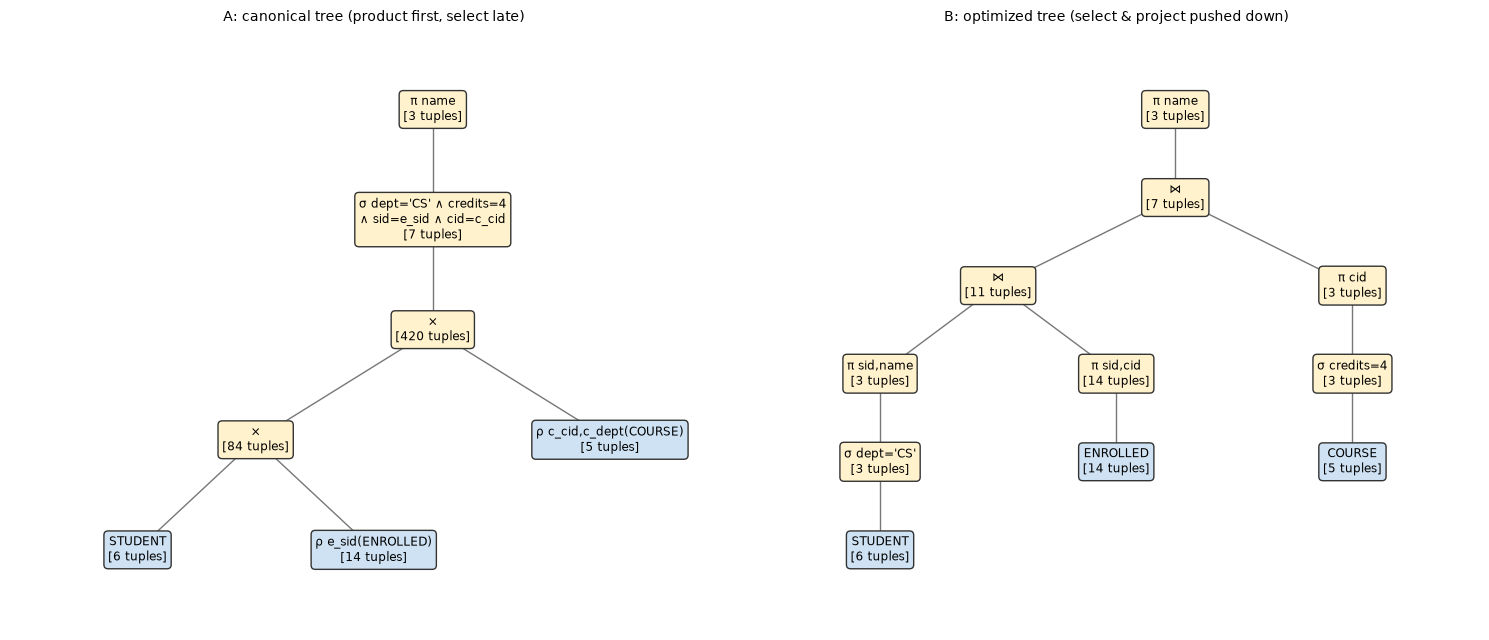

In [20]:
class Node:
    """A node of a relational-algebra expression tree."""
    def __init__(self, label, fn, *children):
        self.label, self.fn, self.children = label, fn, children
        self.result = None

    def eval(self):
        args = [c.eval() for c in self.children]               # evaluate children first (post-order)
        self.result = self.fn(*args)
        return self.result

    def nodes(self):
        yield self
        for c in self.children:
            yield from c.nodes()

def leaf(name, R):
    return Node(name, lambda: R)

def draw_tree(root, ax, title):
    G, pos, labels = nx.DiGraph(), {}, {}
    counter = itertools.count()
    def place(n, depth):                                        # leaves left-to-right, parents centred
        if not n.children:
            x = next(counter)
        else:
            x = sum(place(c, depth + 1) for c in n.children) / len(n.children)
        pos[id(n)] = (x, -depth)
        labels[id(n)] = f"{n.label}\n[{n.result.cardinality} tuples]"
        for c in n.children:
            G.add_edge(id(n), id(c))
        G.add_node(id(n))
        return x
    place(root, 0)
    nx.draw_networkx_edges(G, pos, ax=ax, arrows=False, edge_color="#777")
    for k, (x, y) in pos.items():
        is_leaf = G.out_degree(k) == 0
        ax.text(x, y, labels[k], ha="center", va="center", fontsize=8.5,
                bbox=dict(boxstyle="round,pad=0.35", fc="#cfe2f3" if is_leaf else "#fff2cc", ec="#333"))
    ax.set_title(title, fontsize=10); ax.axis("off"); ax.margins(0.2, 0.12)

# ---- Tree A: canonical translation of the SQL: π(σ(S × E × C))  (rename to avoid name clashes)
S_ = leaf("STUDENT", STUDENT)
E_ = leaf("ρ e_sid(ENROLLED)", rename(ENROLLED, {"sid": "e_sid"}))
Cr = leaf("ρ c_cid,c_dept(COURSE)", rename(COURSE, {"cid": "c_cid", "dept": "c_dept"}))
treeA = Node("π name", lambda r: project(r, ["name"]),
          Node("σ dept='CS' ∧ credits=4\n∧ sid=e_sid ∧ cid=c_cid",
               lambda r: select(r, lambda t: t["dept"] == "CS" and t["credits"] == 4
                                          and t["sid"] == t["e_sid"] and t["cid"] == t["c_cid"]),
               Node("×", product, Node("×", product, S_, E_), Cr)))

# ---- Tree B: selections and projections pushed down, products replaced by natural joins
treeB = Node("π name", lambda r: project(r, ["name"]),
          Node("⋈", natural_join,
               Node("⋈", natural_join,
                    Node("π sid,name", lambda r: project(r, ["sid", "name"]),
                         Node("σ dept='CS'", lambda r: select(r, lambda t: t["dept"] == "CS"), leaf("STUDENT", STUDENT))),
                    Node("π sid,cid", lambda r: project(r, ["sid", "cid"]), leaf("ENROLLED", ENROLLED))),
               Node("π cid", lambda r: project(r, ["cid"]),
                    Node("σ credits=4", lambda r: select(r, lambda t: t["credits"] == 4), leaf("COURSE", COURSE)))))

ra, rb = treeA.eval(), treeB.eval()
assert ra == rb
check(rb, """SELECT DISTINCT s.name FROM student s JOIN enrolled e ON s.sid = e.sid
             JOIN course c ON c.cid = e.cid WHERE s.dept = 'CS' AND c.credits = 4""")
work = lambda root: sum(n.result.cardinality for n in root.nodes() if n.children)
print(f"Intermediate tuples produced — tree A: {work(treeA)}, tree B: {work(treeB)}")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
draw_tree(treeA, axes[0], "A: canonical tree (product first, select late)")
draw_tree(treeB, axes[1], "B: optimized tree (select & project pushed down)")
plt.tight_layout(); plt.show()

**What just happened?** Both trees return the same three names, but tree A first builds a 6 × 14 × 5 = **420**-tuple product (514 intermediate tuples in total), while tree B filters early, never produces more than 14 tuples at any node, and creates only 47 in total. On real tables (millions of rows) this difference is the difference between milliseconds and hours — which is why the **query optimizer** applies these rewrite rules (heuristic optimization) and then picks join orders and algorithms by cost (cost-based optimization). Compare with `EXPLAIN QUERY PLAN` in [notebook 01](01_dbms_introduction_and_architecture.ipynb).

## 7. Joins vs. Nested Queries

> 💡 **In plain English:** the same question can often be written as a join or as a subquery, but `NOT IN` gives wrong answers when NULLs are around.

Many questions can be written either with a join or with a subquery. "Students enrolled in some 4-credit course":

In [21]:
variants = {
    "JOIN + DISTINCT": """SELECT DISTINCT s.sid, s.name FROM student s JOIN enrolled e ON s.sid = e.sid
                          JOIN course c ON c.cid = e.cid WHERE c.credits = 4""",
    "IN subquery":     """SELECT sid, name FROM student WHERE sid IN
                          (SELECT e.sid FROM enrolled e JOIN course c ON c.cid = e.cid WHERE c.credits = 4)""",
    "EXISTS (correlated)": """SELECT sid, name FROM student s WHERE EXISTS
                          (SELECT 1 FROM enrolled e JOIN course c ON c.cid = e.cid
                           WHERE e.sid = s.sid AND c.credits = 4)""",
}
alg = semi_join(project(STUDENT, ["sid", "name"]),
                project(natural_join(ENROLLED, project(select(COURSE, lambda t: t["credits"] == 4), ["cid"])), ["sid"]))
for name, q in variants.items():
    assert sql(q) == alg
    print(f"{name:20} -> {sorted(sql(q).rows)}")
bag_rows = len(db.execute(variants["JOIN + DISTINCT"].replace("DISTINCT", "")).fetchall())
print(f"\nWithout DISTINCT the join returns {bag_rows} rows (duplicates), the semi-join {alg.cardinality}.")

JOIN + DISTINCT      -> [('S1', 'Ayesha'), ('S2', 'Bilal'), ('S4', 'Dina'), ('S5', 'Emre')]
IN subquery          -> [('S1', 'Ayesha'), ('S2', 'Bilal'), ('S4', 'Dina'), ('S5', 'Emre')]
EXISTS (correlated)  -> [('S1', 'Ayesha'), ('S2', 'Bilal'), ('S4', 'Dina'), ('S5', 'Emre')]

Without DISTINCT the join returns 8 rows (duplicates), the semi-join 4.


All three are the **semi-join** STUDENT ⋉ (…). The join version needs `DISTINCT` because a student in two 4-credit courses appears twice; `IN` / `EXISTS` never duplicate. Modern optimizers usually turn `IN`/`EXISTS` into a semi-join internally, so performance is often identical.

**The `NOT IN` + NULL trap.** Negated versions are *not* always equivalent. Which departments have no students?

In [22]:
not_in = db.execute("SELECT dept FROM department WHERE dept NOT IN (SELECT dept FROM student)").fetchall()
not_exists = db.execute("""SELECT dept FROM department d WHERE NOT EXISTS
                           (SELECT 1 FROM student s WHERE s.dept = d.dept)""").fetchall()
anti = anti_join(project(DEPARTMENT, ["dept"]), project(STUDENT, ["dept"]))
print("NOT IN     :", not_in)
print("NOT EXISTS :", not_exists)
print("anti-join  :", sorted(anti.rows))
assert not_in == [] and sorted(not_exists) == sorted(anti.rows) == [("Biology",)]

NOT IN     : []
NOT EXISTS : [('Biology',)]
anti-join  : [('Biology',)]


**What just happened?** Farah's `dept` is NULL, so the subquery returns `{CS, Math, Physics, NULL, …}`. `'Biology' NOT IN (…, NULL)` means `'Biology' ≠ NULL AND …`, and `'Biology' ≠ NULL` is **unknown**, so the whole condition is unknown and the row is dropped — `NOT IN` returns **nothing**. `NOT EXISTS` (and the algebraic anti-join) correctly return Biology.

> ⚠️ **Common mistake:** using `NOT IN (subquery)` on a column that can contain NULL. Prefer `NOT EXISTS`, or add `WHERE col IS NOT NULL` in the subquery.

## 8. Relational Calculus: TRC and DRC

> 💡 **In plain English:** relational calculus describes *what* answer you want using logic ("for all", "there exists") instead of the steps to get it.

Relational algebra is **procedural** (a sequence of operations). **Relational calculus** is **declarative**: you describe the properties of the answer, using first-order logic, and say nothing about how to compute it. SQL's `SELECT … FROM … WHERE` is based on tuple relational calculus.

### 8.1 Tuple relational calculus (TRC)

Form: `{ t | P(t) }` — "the set of tuples t such that predicate P is true". Atoms: `R(t)` (t is a tuple of R, also written t ∈ R), `t.A op s.B`, `t.A op constant`; combined with ∧, ∨, ¬, ⇒ and the quantifiers ∃ (there exists) and ∀ (for all).

| Query | TRC |
|---|---|
| CS students | `{ t | STUDENT(t) ∧ t.dept = 'CS' }` |
| names of students in C1 | `{ t.name | STUDENT(t) ∧ ∃e (ENROLLED(e) ∧ e.sid = t.sid ∧ e.cid = 'C1') }` |
| students in **all** CS courses | `{ t.name | STUDENT(t) ∧ ∀c (COURSE(c) ∧ c.dept = 'CS' ⇒ ∃e (ENROLLED(e) ∧ e.sid = t.sid ∧ e.cid = c.cid)) }` |

### 8.2 Domain relational calculus (DRC)

Variables range over **attribute values** (domains) instead of tuples. Form: `{ <x1, …, xn> | P(x1, …, xn) }`.

| Query | DRC |
|---|---|
| names of CS students | `{ <n> | ∃s, d, y (<s, n, d, y> ∈ STUDENT ∧ d = 'CS') }` |
| names of students in C1 | `{ <n> | ∃s, d, y (<s, n, d, y> ∈ STUDENT ∧ ∃m (<s, 'C1', m> ∈ ENROLLED)) }` |

Python's comprehensions with `any()` (∃) and `all()` (∀) are an almost literal transcription:

In [23]:
student, course, enrolled = list(STUDENT.dicts()), list(COURSE.dicts()), list(ENROLLED.dicts())

# TRC: { t.name | STUDENT(t) ∧ ∃e (ENROLLED(e) ∧ e.sid = t.sid ∧ e.cid = 'C1') }
trc_c1 = {t["name"] for t in student
          if any(e["sid"] == t["sid"] and e["cid"] == "C1" for e in enrolled)}

# TRC with ∀: { t.name | STUDENT(t) ∧ ∀c (COURSE(c) ∧ c.dept='CS' ⇒ ∃e (ENROLLED(e) ∧ e.sid=t.sid ∧ e.cid=c.cid)) }
implies = lambda p, q: (not p) or q
trc_all_cs = {t["name"] for t in student
              if all(implies(c["dept"] == "CS",
                             any(e["sid"] == t["sid"] and e["cid"] == c["cid"] for e in enrolled))
                     for c in course)}

# DRC: { <n> | ∃s,d,y (<s,n,d,y> ∈ STUDENT ∧ d = 'CS') }
drc_cs = {n for (s, n, d, y) in STUDENT.rows if d == "CS"}

print("TRC  in C1        :", sorted(trc_c1))
print("TRC  all CS (∀)   :", sorted(trc_all_cs))
print("DRC  CS students  :", sorted(drc_cs))
assert trc_all_cs == {r[0] for r in q7.rows}                       # same as algebra Q7 (division)
assert trc_c1 == {r[0] for r in sql("SELECT DISTINCT name FROM student NATURAL JOIN enrolled WHERE cid='C1'").rows}
assert drc_cs == {r[0] for r in sql("SELECT name FROM student WHERE dept='CS'").rows}

TRC  in C1        : ['Ayesha', 'Bilal', 'Chen', 'Emre']
TRC  all CS (∀)   : ['Ayesha', 'Bilal', 'Emre']
DRC  CS students  : ['Ayesha', 'Bilal', 'Emre']


### 8.3 Safety of expressions

`{ t | ¬STUDENT(t) }` — "all tuples that are *not* students" — is a legal formula, but its answer is **infinite** (every possible tuple of every possible value that is not in STUDENT). Such an expression is **unsafe**.

An expression is **safe** if every value in its result comes from the **active domain** — the constants appearing in the database relations or in the expression itself. Equivalently, a safe expression is **domain-independent**: its answer does not change if we imagine a bigger universe of values. We can *test* domain independence: evaluate the formula over the active domain, then over the active domain plus one unrelated value.

In [24]:
ENROLLED_SIDS = {r[0] for r in ENROLLED.rows}
STUDENT_SIDS = {r[0] for r in STUDENT.rows}
active_domain = {v for R in (STUDENT, COURSE, ENROLLED, DEPARTMENT) for row in R.rows for v in row if v is not None}

def eval_drc(formula, domain):
    """Evaluate a 1-variable DRC query { <x> | formula(x) } by trying every value of `domain`."""
    return {x for x in domain if formula(x)}

unsafe = lambda x: x not in ENROLLED_SIDS                                # { <x> | ¬ ENROLLED(x, _, _) }
safe = lambda x: x in STUDENT_SIDS and x not in ENROLLED_SIDS             # { <x> | STUDENT(x,…) ∧ ¬ ENROLLED(x,…) }

for name, f in [("unsafe", unsafe), ("safe", safe)]:
    small = eval_drc(f, active_domain)
    big = eval_drc(f, active_domain | {"zzz-anything"})
    print(f"{name:6}: |answer| over active domain = {len(small):2d}, with one extra value = {len(big):2d} "
          f"-> domain-independent? {small == big}")
assert eval_drc(safe, active_domain) == {"S6"}

unsafe: |answer| over active domain = 42, with one extra value = 43 -> domain-independent? False
safe  : |answer| over active domain =  1, with one extra value =  1 -> domain-independent? True


**What just happened?** The unsafe query's answer grew when the universe grew (it returned course titles, buildings, numbers… anything that is not an enrolled sid), so its meaning depends on the domain — unsafe. Restricting `x` to `STUDENT` made it safe: the answer is always {S6} (Farah). SQL guarantees safety syntactically: every variable must range over a table in `FROM`.

> 🎓 **Exam tip — Codd's theorem:** relational algebra, **safe** TRC and **safe** DRC have exactly the **same expressive power**. Any query in one can be translated into the others.

## 9. Codd's Rules and Relational Completeness

> 💡 **In plain English:** Codd's rules are a checklist for a truly relational database, and SQL can express everything the algebra can (and more).

In 1985 E. F. Codd published 12 rules (numbered 0–12, so actually 13) to judge whether a DBMS is *truly* relational. No commercial system satisfies all of them fully (rule 6 on updatable views is the classic failure).

| # | Rule | One-line meaning |
|---|---|---|
| 0 | Foundation | the system must manage databases entirely through its relational capabilities |
| 1 | Information | all information is represented as values in tables |
| 2 | Guaranteed access | every value is reachable by *table name + primary key + column name* |
| 3 | Systematic NULLs | NULL is supported uniformly for missing/inapplicable data, distinct from 0 or '' |
| 4 | Dynamic online catalog | the catalog is itself stored in relations, queryable with the same language (`sqlite_master`, `information_schema`) |
| 5 | Comprehensive data sublanguage | one language for definition, manipulation, constraints, authorization, transactions (SQL) |
| 6 | View updating | all theoretically updatable views are updatable by the system |
| 7 | High-level insert/update/delete | set-at-a-time operations, not just row-at-a-time |
| 8 | Physical data independence | storage changes do not affect programs |
| 9 | Logical data independence | logical changes (e.g. splitting tables) do not affect programs (via views) |
| 10 | Integrity independence | constraints are defined in the catalog, not in application programs |
| 11 | Distribution independence | users need not know whether data is distributed |
| 12 | Non-subversion | low-level (record-at-a-time) interfaces cannot bypass integrity rules |

**Relational completeness** (Codd, 1972): a query language is *relationally complete* if it can express every query of relational algebra (equivalently, of safe relational calculus). SQL is relationally complete — and goes further with aggregation, ordering, bags, and recursion (`WITH RECURSIVE`, SQL:1999). Classic limitation: basic relational algebra **cannot express transitive closure** (e.g. "all prerequisites of a course, at any depth"), because each expression joins a fixed number of times. Recursive SQL can:

In [25]:
rc = sqlite3.connect(":memory:")
rc.executescript("""
CREATE TABLE prereq(course TEXT, pre TEXT);
INSERT INTO prereq VALUES ('ML','Stats'), ('Stats','Calculus'), ('Calculus','Algebra'), ('ML','Python');
""")
closure = rc.execute("""
WITH RECURSIVE needs(course, pre) AS (
    SELECT course, pre FROM prereq                        -- base case: direct prerequisites
    UNION
    SELECT n.course, p.pre FROM needs n JOIN prereq p ON n.pre = p.course   -- one more step
)
SELECT pre FROM needs WHERE course = 'ML' ORDER BY pre""").fetchall()
print("All prerequisites of ML:", [r[0] for r in closure])

# The same as a fixed point of algebra operations, repeated until nothing changes (a loop, not ONE expression)
P = Relation(["course", "pre"], rc.execute("SELECT * FROM prereq").fetchall())
T = P
while True:
    step = project(natural_join(rename(T, ["course", "mid"]), rename(P, ["mid", "pre"])), ["course", "pre"])
    new = union(T, step)
    if new == T:
        break
    T = new
assert sorted(r[1] for r in T.rows if r[0] == "ML") == [r[0] for r in closure]
print("Fixed-point iteration agrees ✔ (needed", T.cardinality, "tuples)")
rc.close()

All prerequisites of ML: ['Algebra', 'Calculus', 'Python', 'Stats']
Fixed-point iteration agrees ✔ (needed 7 tuples)


## 10. Row-Oriented vs. Column-Oriented Storage

> 💡 **In plain English:** a row store keeps each record together (good for fetching one customer); a column store keeps each column together (good for averages over millions of rows).

The relational model says nothing about how tuples sit on disk (physical data independence). Two main layouts:

```
Row store (NSM, "n-ary storage model")          Column store (DSM, "decomposition storage model")
page 1: [S1,Ayesha,CS,2][S2,Bilal,CS,3]...     sid page : S1 S2 S3 S4 ...
page 2: [S5,Emre,CS,4][S6,Farah,NULL,3]...     name page: Ayesha Bilal Chen ...
                                                dept page: CS CS Math Physics ...
```

- **Row stores** keep each tuple together: great for **OLTP** (fetch/insert/update one whole record). PostgreSQL, MySQL/InnoDB, SQL Server (default), Oracle, SQLite.
- **Column stores** keep each attribute together: great for **OLAP/analytics** (scan a few columns of many rows), and columns of one type **compress** extremely well. DuckDB, ClickHouse, Snowflake, BigQuery, Redshift, Vertica; file formats Parquet and ORC.

Let us measure both with a from-scratch simulation: count pages read, and time real Python code.

In [26]:
rng = np.random.default_rng(0)
N, PAGE = 200_000, 4096                         # rows; bytes per page
cols = {"id": np.arange(N, dtype=np.int64),
        "dept": np.sort(rng.integers(0, 8, N)).astype(np.int64),   # sorted, low cardinality
        "year": rng.integers(1, 5, N).astype(np.int64),
        "marks": rng.normal(70, 10, N),
        "credits": rng.integers(1, 6, N).astype(np.int64),
        "fee": rng.normal(5000, 800, N),
        "lat": rng.normal(31.5, 0.1, N),
        "lon": rng.normal(74.3, 0.1, N)}
ROW_BYTES = 8 * len(cols)                        # 8 columns of 8 bytes each

row_store = list(zip(*[c.tolist() for c in cols.values()]))       # list of tuples (one per record)
col_store = {k: v for k, v in cols.items()}                         # dict of contiguous arrays

pages_row_scan = math.ceil(N * ROW_BYTES / PAGE)                    # must read every page
pages_col_scan = math.ceil(N * 8 / PAGE)                            # only the 'marks' column
pages_row_point, pages_col_point = 1, len(cols)                     # one record: 1 page vs 1 page per column

t0 = time.perf_counter(); avg_row = sum(r[3] for r in row_store) / N; t_row = time.perf_counter() - t0
t0 = time.perf_counter(); avg_col = col_store["marks"].mean();          t_col = time.perf_counter() - t0
assert abs(avg_row - avg_col) < 1e-6

io = pd.DataFrame({"row store": [pages_row_scan, pages_row_point], "column store": [pages_col_scan, pages_col_point]},
                  index=["AVG(marks) over all rows: pages read", "fetch one full record: pages read"])
print(io)
print(f"\nAVG(marks): row store {t_row*1000:.1f} ms, column store {t_col*1000:.2f} ms  (same answer {avg_col:.3f})")

# Compression: run-length encoding of the sorted, low-cardinality 'dept' column
def rle(a):
    """Run-length encode an array into (value, run_length) pairs."""
    change = np.flatnonzero(np.diff(a)) + 1
    starts = np.r_[0, change]
    lengths = np.diff(np.r_[starts, len(a)])
    return list(zip(a[starts].tolist(), lengths.tolist()))
runs = rle(col_store["dept"])
assert np.array_equal(np.repeat([v for v, _ in runs], [n for _, n in runs]), col_store["dept"])   # lossless
print(f"RLE on dept: {N:,} values -> {len(runs)} runs (compression ×{N / len(runs):,.0f})")

                                      row store  column store
AVG(marks) over all rows: pages read       3125           391
fetch one full record: pages read             1             8

AVG(marks): row store 19.1 ms, column store 0.48 ms  (same answer 70.002)
RLE on dept: 200,000 values -> 8 runs (compression ×25,000)


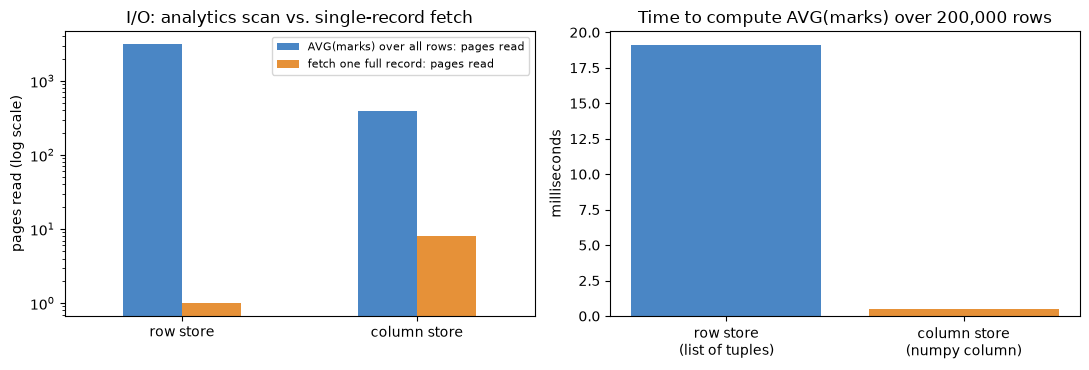

In [27]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
io.T.plot.bar(ax=ax[0], rot=0, color=["#4a86c5", "#e69138"])
ax[0].set_yscale("log"); ax[0].set_ylabel("pages read (log scale)")
ax[0].set_title("I/O: analytics scan vs. single-record fetch"); ax[0].legend(fontsize=8)
ax[1].bar(["row store\n(list of tuples)", "column store\n(numpy column)"], [t_row * 1000, t_col * 1000],
          color=["#4a86c5", "#e69138"])
ax[1].set_ylabel("milliseconds"); ax[1].set_title(f"Time to compute AVG(marks) over {N:,} rows")
plt.tight_layout(); plt.show()

**What just happened?** For the analytic query the column store reads only the `marks` column — **8× fewer pages** here (8 columns) — and the contiguous numeric array is processed by vectorized code dozens of times faster. For fetching one complete record the row store wins (1 page vs. 8). The sorted `dept` column compressed from 200,000 values to just 8 runs. That is why OLTP systems are row stores and data warehouses are column stores, and why "HTAP" systems keep both.

| | Row store | Column store |
|---|---|---|
| Best for | OLTP: point lookups, inserts, updates of whole rows | OLAP: scans and aggregates over few columns |
| Reads for `SELECT AVG(x)` | all columns of all rows | only column x |
| Insert one row | 1 page write | 1 write per column (often batched) |
| Compression | moderate | excellent (RLE, dictionary, bit-packing) |
| Examples | PostgreSQL, MySQL, Oracle, SQLite | DuckDB, ClickHouse, Snowflake, BigQuery, Parquet |

## 🔗 How this connects to modern AI

> 💡 **In plain English:** pandas, feature pipelines and text-to-SQL agents all use these same table operations under the hood.

- **Dataframes are relational algebra.** `df[df.dept == 'CS']` is σ, `df[['name']]` is π, `merge` is ⋈ (with `how='left'/'right'/'outer'` for outer joins, `indicator=True` for anti-joins), `groupby().agg()` is γ. Knowing the algebra makes pandas, Polars and Spark feel like one tool ([pandas](../../02_Data_Analysis/03_pandas.ipynb), [Polars](../../02_Data_Analysis/09_polars.ipynb)).
- **Feature engineering = joins + aggregations.** Training sets are built with point-in-time joins and γ aggregates over event tables — see [SQL for ML feature extraction](../01_sql/02_industry_sql_for_ml_feature_extraction.ipynb). The `NOT IN`/NULL trap silently drops training rows.
- **Column stores power ML data.** Parquet + DuckDB/Polars read only the feature columns a model needs ([DuckDB](../../02_Data_Analysis/10_duckdb.ipynb)); LLM training corpora are commonly stored as Parquet shards.
- **Text-to-SQL and query optimizers.** LLM agents that generate SQL benefit from algebra-level checks (e.g. "all" questions need division-style queries). Learned query optimizers use ML to estimate cardinalities — the numbers we printed under each tree node.
- **Relational calculus ↔ logic.** TRC/DRC are first-order logic; Datalog extends them with recursion and is used in knowledge-graph reasoning and program analysis ([Knowledge graphs](../../08_LLM/09_knowledge_graphs)).
- **Vector search meets algebra.** "Top-k similar documents *where* tenant = X" is a selection combined with a nearest-neighbour operator — filtered vector search ([Vector DBs](../03_vector_db/01_vector_databases.ipynb)).

In [28]:
db.close(); ic.close()
print("connections closed")

connections closed


## Recap

> 💡 **In plain English:** the key ideas in a few bullets, then practice problems to check you really understood them.

- A **relation** is a set of tuples over attribute **domains**: no duplicates, no order, atomic values; **degree** = #attributes, **cardinality** = #tuples; **schema** (structure) vs. **instance** (state).
- **Keys**: superkey ⊇ candidate key (minimal) → one chosen as **primary**, others **alternate**; **foreign keys** link relations; **surrogate** keys are system-generated. Data can refute but never prove a key; brute force is O(2^n · m).
- **Integrity constraints**: domain, key, entity (PK not NULL), referential (`CASCADE`, `SET NULL`, `RESTRICT`, …), check. In SQLite turn on `PRAGMA foreign_keys`, use `NOT NULL` on non-integer PKs and `STRICT` tables.
- **Relational algebra**: fundamental σ, π, ρ, ∪, −, ×; derived ∩, joins, ÷; extended outer joins, ⋉, ▷, γ. Closed under composition → expression trees, which optimizers rewrite (push σ/π down).
- Exam patterns: *not* → difference/anti-join; *all* → division / double `NOT EXISTS`; *max without aggregates* → difference trick; *at least two* → self-join.
- **TRC** `{t | P(t)}` and **DRC** `{<x…> | P}` are declarative; only **safe** (domain-independent) expressions are allowed; algebra ≡ safe TRC ≡ safe DRC (Codd's theorem).
- Codd's 12 rules define "truly relational"; SQL is relationally complete (and more). Row stores suit OLTP, column stores suit OLAP.

## Practice problems

**1. (Easy)** R(A, B, C) has 4 tuples and S(C, D) has 3 tuples. What are the degree and the maximum cardinality of (a) R × S, (b) R ⋈ S, (c) π<sub>A</sub>(R)? What is the minimum cardinality of R ⋈ S?
<details><summary>Show solution</summary>

(a) degree 5, cardinality exactly 12. (b) degree 4 (C appears once), at most 12 (if every tuple of R matches every tuple of S), at least 0. (c) degree 1, at most 4 (fewer if A-values repeat).
</details>

**2. (Easy)** How many superkeys does R(A, B, C, D, E) have if its only candidate keys are {A} and {B, C}?
<details><summary>Show solution</summary>

|SK containing A| = 2^4 = 16; |SK containing B and C| = 2^3 = 8; containing A, B and C = 2^2 = 4. Total = 16 + 8 − 4 = **20**. Check in code:
```python
r = Relation("ABCDE", [(1, 1, 1, 0, 0), (2, 1, 2, 0, 0), (3, 2, 1, 0, 0), (4, 2, 2, 0, 0)])
print(candidate_keys(r), len(all_superkeys(r)))   # [('A',), ('B', 'C')] 20
```
</details>

**3. (Medium)** Write in relational algebra and test with our functions: *names of students who are enrolled in some course of their own department.*
<details><summary>Show solution</summary>

π<sub>name</sub>(STUDENT ⋈ ENROLLED ⋈ π<sub>cid,dept</sub>(COURSE)) — the natural join on both `sid` and `dept` enforces "own department".
```python
ans = project(natural_join(natural_join(STUDENT, ENROLLED), project(COURSE, ["cid", "dept"])), ["name"])
print(sorted(ans.rows))   # [('Ayesha',), ('Bilal',), ('Chen',), ('Dina',), ('Emre',)]
```
(Requires re-opening `db` if you want to compare with SQL, because the last cell closed it.)
</details>

**4. (Medium)** Express R ÷ S using only σ, π, ×, − for R(A, B) and S(B). Then explain why R ÷ S is not defined if S has an attribute not in R.
<details><summary>Show solution</summary>

R ÷ S = π<sub>A</sub>(R) − π<sub>A</sub>((π<sub>A</sub>(R) × S) − R). The definition needs attrs(S) ⊆ attrs(R): the result has the attributes attrs(R) − attrs(S), and we must be able to look up every (a, s) combination *inside R*. If S had an extra attribute D, no tuple of R could ever contain a D-value, so "paired with every tuple of S" is meaningless (and the difference above would be ill-typed).
</details>

**5. (Medium, coding)** Implement `natural_join_nested_loop(R, S)` (no hashing) and assert that it equals `natural_join` on `STUDENT` and `ENROLLED`. What are the two algorithms' time complexities?
<details><summary>Show solution</summary>

```python
def natural_join_nested_loop(R, S):
    common = [a for a in R.attrs if a in S.attrs]
    rest = [a for a in S.attrs if a not in common]
    out = []
    for r in R.dicts():
        for s in S.dicts():
            if all(r[c] is not None and r[c] == s[c] for c in common):
                out.append(tuple(r.values()) + tuple(s[a] for a in rest))
    return Relation(R.attrs + tuple(rest), out)

assert natural_join_nested_loop(STUDENT, ENROLLED) == natural_join(STUDENT, ENROLLED)
```
Nested loop: O(|R|·|S|). Hash join: O(|R| + |S| + |output|) expected time, O(|S|) extra memory.
</details>

**6. (Medium)** Write in TRC: *the titles of courses that no student has enrolled in.* Is your expression safe?
<details><summary>Show solution</summary>

`{ c.title | COURSE(c) ∧ ¬∃e (ENROLLED(e) ∧ e.cid = c.cid) }`. It is **safe**: `c` is bound to COURSE, so every answer value comes from the database (the negation only filters). With our data the answer is empty — every course has at least one student.
</details>

**7. (Hard)** Show with a tiny example that left outer join is **not associative**: find R(A,B), S(B,C), T(C,D) or similar with (R ⟕ S) ⟕ T ≠ R ⟕ (S ⟕ T)… *or* explain why for natural outer joins with these schemas the two sides are equal, and give a case (e.g. mixing inner and outer joins) where the order matters.
<details><summary>Show solution</summary>

With chain schemas R(A,B), S(B,C), T(C,D), left outer joins happen to be associative. Order *does* matter when inner and outer joins are mixed:
```python
R = Relation(["A", "B"], [(1, "x")])
S = Relation(["B", "C"], [])                      # no partner for B='x'
T = Relation(["C", "D"], [("c", 9)])
left = natural_join(left_outer_join(R, S), T)     # (R ⟕ S) ⋈ T : C is NULL -> no match -> empty
right = left_outer_join(R, natural_join(S, T))    # R ⟕ (S ⋈ T) : keeps (1, 'x', NULL, NULL)
print(left.cardinality, right.cardinality)       # 0 1
```
This is why SQL engines must respect the written placement of outer joins when reordering.
</details>

**8. (Hard)** Using `Node` and `draw_tree`, build two trees for *"titles of courses taken by Physics students"* — one canonical (products first) and one optimized — assert equal results and compare intermediate tuple counts.
<details><summary>Show solution</summary>

```python
A = Node("π title", lambda r: project(r, ["title"]),
      Node("σ dept='Physics' ∧ sid=e_sid ∧ cid=c_cid",
           lambda r: select(r, lambda t: t["dept"] == "Physics" and t["sid"] == t["e_sid"] and t["cid"] == t["c_cid"]),
           Node("×", product, Node("×", product, leaf("STUDENT", STUDENT), leaf("ρE", rename(ENROLLED, {"sid": "e_sid"}))),
                leaf("ρC", rename(COURSE, {"cid": "c_cid", "dept": "c_dept"})))))
B = Node("π title", lambda r: project(r, ["title"]),
      Node("⋈", natural_join,
           Node("⋈", natural_join,
                Node("π sid", lambda r: project(r, ["sid"]),
                     Node("σ dept='Physics'", lambda r: select(r, lambda t: t["dept"] == "Physics"), leaf("STUDENT", STUDENT))),
                Node("π sid,cid", lambda r: project(r, ["sid", "cid"]), leaf("ENROLLED", ENROLLED))),
           Node("π cid,title", lambda r: project(r, ["cid", "title"]), leaf("COURSE", COURSE))))
assert A.eval() == B.eval()        # {('Mechanics',)}
print(work(A), work(B))            # 506 vs. 24
```
</details>

## Further reading

- Silberschatz, Korth & Sudarshan, *Database System Concepts*, 7th ed., **Chapter 2** (Intro to the Relational Model), **Chapter 27** (Formal Relational Query Languages: algebra, TRC, DRC), Chapter 16 (Query Optimization).
- Elmasri & Navathe, *Fundamentals of Database Systems*, 7th ed., **Chapter 5** (Relational Model and Constraints), **Chapter 8** (Relational Algebra and Relational Calculus).
- E. F. Codd, "A Relational Model of Data for Large Shared Data Banks", *Communications of the ACM* 13(6), 1970 — the paper that started it all.
- Abiteboul, Hull & Vianu, *Foundations of Databases* (free online), chapters on the relational calculus and domain independence.
- GeeksforGeeks DBMS tutorial — Relational Model, Relational Algebra and Relational Calculus sections; CMU 15-445 lectures on query execution and optimization.

## Next notebook

➡️ [04 — Functional Dependencies and Normalization](04_functional_dependencies_and_normalization.ipynb): how to find keys *from the schema* (attribute closure) and remove redundancy with normal forms. To put the algebra to work in real SQL, see [SQL Fundamentals](../01_sql/01_sql_fundamentals.ipynb) (joins, CTEs, window functions, transactions).